# Dự đoán khách có mua lại trong 90 ngày tới không — Online Retail II

**Câu hỏi:** Trong số khách đang hoạt động, ai nhiều khả năng sẽ mua lại trong 90 ngày tới? Kết quả dùng để xếp hạng khách khi chọn đối tượng giữ chân hoặc khuyến mãi.

**Đầu vào:** `weekly_rfm.csv` do `02_rfm_segmentation.ipynb` tạo ra.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.float_format", "{:,.3f}".format)

HORIZON = 13
R_MAX = 90   

w = pd.read_csv("weekly_rfm.csv", parse_dates=["snapshot_date"])
w = w.sort_values(["CustomerID", "snapshot_date"]).reset_index(drop=True)
print(f"{len(w):,} rows | {w['CustomerID'].nunique():,} customers | {w['snapshot_date'].min().date()} to {w['snapshot_date'].max().date()}")
w[["CustomerID", "snapshot_date", "recency_days", "frequency", "monetary", "frequency_week", "segment"]].head()

394,694 rows | 5,835 customers | 2009-12-07 to 2011-12-05


,CustomerID,snapshot_date,recency_days,frequency,monetary,frequency_week,segment
0,12346,2010-03-08,5,1,27.050,1,One-time recent
1,12346,2010-03-15,12,1,27.050,0,One-time recent
2,12346,2010-03-22,19,1,27.050,0,One-time recent
3,12346,2010-03-29,26,1,27.050,0,One-time recent
4,12346,2010-04-05,33,1,27.050,0,One-time recent


## 1. Thông tin dùng để dự đoán và điều cần dự đoán

Năm con số, tất cả tính **đến hết ngày snapshot**:

| Tên | Ý nghĩa |
|---|---|
| `recency_days` | Số ngày kể từ lần mua cuối |
| `frequency` | Tổng số hóa đơn từ trước đến nay |
| `monetary` | Tổng chi tiêu ròng từ trước đến nay |
| `orders_last_90d` | Số hóa đơn trong 90 ngày gần nhất |
| `tenure_days` | Số ngày kể từ lần mua đầu tiên |

**Điều cần dự đoán** (`bought`) lấy từ tương lai: `frequency` của chính khách đó 13 tuần sau có lớn hơn `frequency` hiện tại không. Nhãn chỉ dùng để huấn luyện và chấm điểm, không bao giờ đưa vào năm con số trên.

In [2]:
by_customer = w.groupby("CustomerID")
assert (by_customer["snapshot_date"].diff().dropna() == pd.Timedelta(days=7)).all()     # one row per week, so 13 rows = 13 weeks

# Five numbers known at the snapshot date
w["tenure_days"] = (w["snapshot_date"] - by_customer["snapshot_date"].transform("min")).dt.days
w["orders_last_90d"] = by_customer["frequency_week"].transform(lambda s: s.rolling(HORIZON, min_periods=1).sum())
FEATURES = ["recency_days", "frequency", "monetary", "orders_last_90d", "tenure_days"]

# What we want to predict: did the customer place an order in the next 13 weeks?
next_frequency = by_customer["frequency"].shift(-HORIZON)
w["bought"] = (next_frequency > w["frequency"]).astype(float).where(next_frequency.notna())
w[["CustomerID", "snapshot_date"] + FEATURES + ["bought"]].tail(3)

,CustomerID,snapshot_date,recency_days,frequency,monetary,orders_last_90d,tenure_days,bought
394691,18287,2011-11-21,23,7,"4,127.890",2.000,546,NaN
394692,18287,2011-11-28,30,7,"4,127.890",2.000,553,NaN
394693,18287,2011-12-05,37,7,"4,127.890",2.000,560,NaN


## 2. Chia train và test theo thời gian

* Chỉ giữ **khách đang hoạt động** (mua trong 90 ngày gần nhất). Khách đã rời đi ngày càng nhiều trong bảng và sẽ làm tỷ lệ mua giảm dần theo thời gian.
* **Train:** các snapshot đến 2011-02-28. Nhãn của chúng nhìn tới 2011-05-30.
* **Test:** các snapshot từ 2011-06-06. Vì 2011-05-30 nhỏ hơn 2011-06-06, không nhãn nào của train nhìn vào giai đoạn của test.
* **Chọn mẫu train:** mỗi khách chỉ lấy một snapshot mỗi 13 tuần. Các tuần liền kề của cùng một khách gần như giống nhau, lấy hết chỉ làm mô hình tưởng mình có nhiều dữ liệu hơn thật.

**Mốc thời gian (theo ngày snapshot):**

| Phần | Các snapshot | Ghi chú |
|---|---|---|
| Train | 2009-12-07 đến 2011-02-28 | |
| Khoảng trống | 2011-03-07 đến 2011-05-30 | Bỏ, dài 13 tuần bằng độ dài của nhãn |
| Test | 2011-06-06 đến 2011-09-05 | 14 tuần, chấm một lần |
| Sau đó | 2011-09-12 đến 2011-12-05 | Chưa có nhãn, chỉ dùng chấm điểm khách (mục 6) |

Lưu ý: test chỉ có 14 tuần, và train chỉ thấy một mùa cao điểm.

In [ ]:
active = w[w["recency_days"] <= R_MAX]
labeled = active.dropna(subset=["bought"])

train = labeled[labeled["snapshot_date"] <= "2011-02-28"]
test = labeled[labeled["snapshot_date"] >= "2011-06-06"]
assert train["snapshot_date"].max() + pd.Timedelta(weeks=HORIZON) < test["snapshot_date"].min()

train = train[(train["tenure_days"] // 7) % HORIZON == 0]              

pd.DataFrame({"rows": [len(train), len(test)],
              "customers": [train["CustomerID"].nunique(), test["CustomerID"].nunique()],
              "share_who_bought": [train["bought"].mean(), test["bought"].mean()]}, index=["train", "test"])

,rows,customers,share_who_bought
train,10520,4500,0.554
test,27696,2794,0.623


## 3. Cách đo kết quả

Mô hình cho mỗi khách một điểm (xác suất mua lại). Ta xếp khách theo điểm giảm dần và hỏi: những khách đứng đầu bảng có thật sự hay mua hơn không?

* **ROC-AUC, PR-AUC:** đo chất lượng cả bảng xếp hạng. ROC-AUC = 0.5 là xếp hạng ngẫu nhiên. PR-AUC nên so với tỷ lệ khách mua chung.
* **Precision@10%:** trong 10% khách có điểm cao nhất, bao nhiêu % thật sự mua.
* **Lift@10%:** Precision@10% chia cho tỷ lệ mua chung. Lift 2 nghĩa là nhóm đứng đầu mua gấp đôi mức trung bình.
* **Gain@10%:** 10% khách đứng đầu chứa bao nhiêu % tổng số người sẽ mua.

In [ ]:
def evaluate(y, score, k=0.10):
    top = np.argsort(-score)[: int(k * len(y))]
    precision = y[top].mean()
    return {"ROC-AUC": roc_auc_score(y, score), "PR-AUC": average_precision_score(y, score),
            "Precision@10%": precision, "Lift@10%": precision / y.mean(), "Gain@10%": y[top].sum() / y.sum()}

y_test = test["bought"].values
random_score = np.random.default_rng(0).random(len(test))
recency_score = -test["recency_days"].values                                  

scaler = StandardScaler().fit(np.log1p(train[FEATURES]))                 
prepare = lambda df: scaler.transform(np.log1p(df[FEATURES]))
model = LogisticRegression(max_iter=1000).fit(prepare(train), train["bought"])
test_p = model.predict_proba(prepare(test))[:, 1]

pd.DataFrame({"Random": evaluate(y_test, random_score), "Recency rule": evaluate(y_test, recency_score),
              "Logistic Regression": evaluate(y_test, test_p)}).T

,ROC-AUC,PR-AUC,Precision@10%,Lift@10%,Gain@10%
Random,0.498,0.624,0.635,1.019,0.102
Recency rule,0.603,0.694,0.731,1.173,0.117
Logistic Regression,0.762,0.849,0.963,1.546,0.155


## 4. Xác suất có đáng tin không (calibration)

Calibration trả lời: **khi mô hình nói "khách này có 30% khả năng mua lại", con số 30% đó có đúng không?**

* **Xếp hạng đúng** (ROC-AUC, Precision@10%): mô hình biết khách A dễ mua hơn khách B.
* **Con số đúng** (calibration): trong số khách mà mô hình cho 30%, khoảng 30% phải thật sự mua. Một mô hình có thể xếp hạng rất tốt nhưng con số lệch (ví dụ luôn nói 60% trong khi thực tế 40%).

**Cách đọc:** biểu đồ chia khách thành 10 nhóm theo điểm, so xác suất dự đoán (ngang) với tỷ lệ mua thực tế (dọc). Càng gần đường chéo càng đáng tin. Nằm dưới đường chéo là mô hình quá lạc quan, nằm trên là quá bi quan. **Brier skill** lớn hơn 0 nghĩa là tốt hơn việc luôn đoán tỷ lệ mua chung.

**Kết quả:** dự đoán trung bình 0.639, thực tế 0.623, khá sát. Mô hình hơi lạc quan ở khoảng giữa (dự đoán khoảng 60%, thực tế khoảng 53%) và đúng ở hai đầu.

**Vì sao quan trọng:** khi tính lợi nhuận của một ưu đãi, ta dùng chính con số này (khách có bao nhiêu % sẽ mua dù không có ưu đãi), nên nếu nó lệch thì phép tính lợi nhuận lệch theo. Nếu chỉ xếp hạng rồi chọn top N khách thì calibration ít quan trọng hơn.

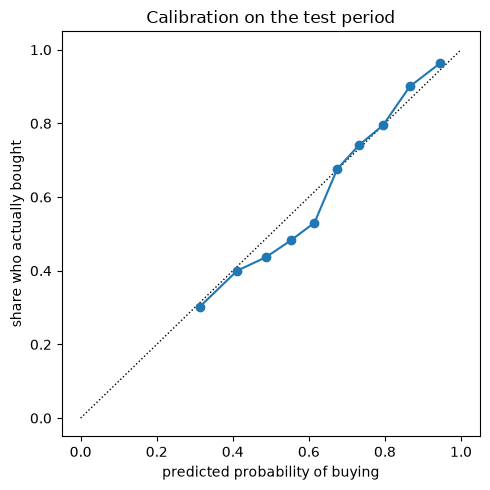

Average predicted: 0.639 | actually bought: 0.623 | Brier skill: 0.189


In [5]:
observed, predicted = calibration_curve(y_test, test_p, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.plot(predicted, observed, "o-", color="tab:blue")
ax.set_xlabel("predicted probability of buying"); ax.set_ylabel("share who actually bought")
ax.set_title("Calibration on the test period"); plt.tight_layout(); plt.show()

brier, brier_base = brier_score_loss(y_test, test_p), y_test.mean() * (1 - y_test.mean())
print(f"Average predicted: {test_p.mean():.3f} | actually bought: {y_test.mean():.3f} | Brier skill: {1 - brier / brier_base:.3f}")

## 5. Điều gì đẩy xác suất lên hoặc xuống

Mỗi cột là hệ số của một con số sau khi đã đưa về cùng thang. Cột dương: giá trị càng cao thì khách càng dễ mua lại. Cột âm: ngược lại. Đây là liên hệ mô hình học được từ dữ liệu, **không phải bằng chứng một yếu tố gây ra việc mua lại**.

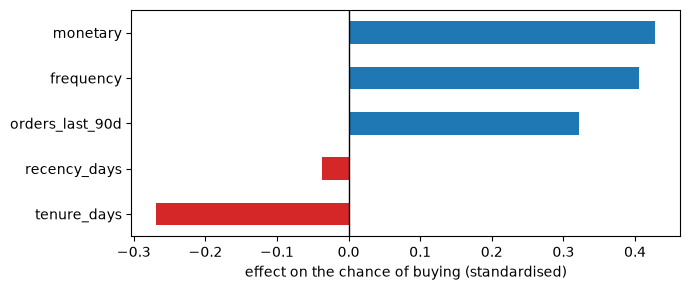

In [6]:
coef = pd.Series(model.coef_[0], index=FEATURES).sort_values()
ax = coef.plot.barh(color=["tab:red" if v < 0 else "tab:blue" for v in coef], figsize=(7, 3))
ax.axvline(0, color="k", lw=1); ax.set_xlabel("effect on the chance of buying (standardised)")
plt.tight_layout(); plt.show()

## 6. Bảng điểm theo khách

Chấm điểm cho khách đang hoạt động ở snapshot mới nhất (2011-12-05): xác suất mua lại trong 90 ngày tới, sắp xếp từ cao xuống thấp. Kèm nhóm hiện tại ở notebook 02 để dễ đọc. Lưu vào `customer_scores.csv`.

In [7]:
latest = active[active["snapshot_date"] == active["snapshot_date"].max()]
scores = (latest[["CustomerID", "segment", "recency_days", "frequency", "monetary"]]
          .assign(p_buy_next_90d=model.predict_proba(prepare(latest))[:, 1])
          .sort_values("p_buy_next_90d", ascending=False))
scores.to_csv("customer_scores.csv", index=False)
print(f"Saved customer_scores.csv: {len(scores):,} active customers")
scores.head(5)

Saved customer_scores.csv: 2,867 active customers


,CustomerID,segment,recency_days,frequency,monetary,p_buy_next_90d
168623,14911,Champions,0,367,"253,044.000",0.999
23241,12748,Champions,0,317,"45,974.050",0.999
382681,18102,Champions,6,142,"566,923.100",0.998
150493,14646,Champions,11,142,"511,474.720",0.998
365118,17841,Champions,2,209,"65,493.470",0.998


## Nhận xét

**Dữ liệu:** train có 10,520 dòng (4,500 khách), 55.4% mua lại trong 90 ngày. Test có 27,696 dòng (2,794 khách), 62.3% mua lại. Nhờ chỉ giữ khách đang hoạt động, tỷ lệ mua giữa hai giai đoạn khá gần nhau.

**Vì sao ngưỡng "đang hoạt động" là 90 ngày:** đây là cùng quy tắc với luật phân nhóm ở notebook 02 (R không quá 90 thì khách còn active). Trên dữ liệu này, tỷ lệ mua lại giảm dần đều theo số ngày chưa mua và không có điểm gãy rõ, nên 90 là một mốc quy ước, không phải ngưỡng tự nhiên. Các mốc khác (như P90 khoảng cách giữa hai lần mua là 148 ngày) cũng bảo vệ được và sẽ cho kết quả hơi khác.

**Kết quả trên giai đoạn test:**

| | ROC-AUC | PR-AUC | Precision@10% | Lift@10% | Gain@10% |
|---|---|---|---|---|---|
| Ngẫu nhiên | 0.498 | 0.624 | 0.635 | 1.02 | 0.102 |
| Quy tắc recency | 0.603 | 0.694 | 0.731 | 1.17 | 0.117 |
| **Logistic Regression** | **0.762** | **0.849** | **0.963** | **1.55** | **0.155** |

* Mô hình hơn rõ quy tắc "ai mua gần đây hơn thì điểm cao hơn". Trong 10% khách có điểm cao nhất, **96.3%** thật sự mua lại, so với 73.1% của quy tắc recency và 62.3% mức chung.
* Lift@10% bị chặn ở mức tối đa khoảng 1.61 (1 chia cho 0.623) vì hơn một nửa khách đều mua. Vì vậy với bài toán này nên đọc Precision@10% và PR-AUC hơn là Lift.
* Quy tắc recency yếu vì khi chỉ giữ khách mua trong 90 ngày gần nhất thì khoảng cách recency giữa các khách nhỏ đi, ít phân biệt được hơn.

**Xác suất có đáng tin không:**
* Xác suất dự đoán trung bình là 0.639, tỷ lệ mua thật là 0.623, khá sát. Brier skill 0.189, tốt hơn việc luôn đoán tỷ lệ chung.
* Biểu đồ calibration nằm gần đường chéo. Mô hình hơi lạc quan ở khoảng giữa (dự đoán khoảng 60% nhưng thực tế khoảng 53%) và đúng ở hai đầu. Dùng được để xếp hạng, và dùng được cho xác suất ở mức xấp xỉ.

**Điều gì đẩy xác suất lên hoặc xuống:**
* Khách có **chi tiêu nhiều**, **nhiều hóa đơn** và **mua nhiều trong 90 ngày gần nhất** có xác suất mua lại cao hơn.
* `tenure_days` có hệ số âm: khi các con số khác như nhau, khách đã gắn bó lâu hơn lại ít mua lại hơn một chút.
* `recency_days` gần như không có hệ số riêng, nhưng điều đó **không có nghĩa recency không quan trọng**: nó bị `orders_last_90d` và `frequency` gánh phần lớn thông tin tương tự, và các khách ở đây đều đã mua trong 90 ngày.

**Đã thử tối ưu nhưng không giữ lại:** thêm đặc trưng nhịp mua, chi tiêu, xu hướng và mùa vụ, đổi sang Random Forest hoặc gradient boosting, và hiệu chỉnh xác suất trên validation. Không cách nào cải thiện ổn định khả năng xếp hạng (ROC-AUC trên validation của bộ 5 con số hiện tại là 0.782, cao nhất trong các bộ thử). Gradient boosting cho ROC-AUC cao hơn 0.012 trên test nhưng lại kém trên validation, nên khác biệt này nhiều khả năng là nhiễu. Hiệu chỉnh trên validation làm calibration tệ hơn vì tỷ lệ mua lại thay đổi theo mùa (khoảng 48% đến 51% ở các quý 4 và 1, 64% ở quý 3 năm 2011). Vì vậy giữ nguyên mô hình đơn giản này.

**Bảng điểm:** `customer_scores.csv` có 2,867 khách đang hoạt động ở snapshot 2011-12-05, xác suất trung bình 0.638. Gồm 1,328 Loyal, 649 Developing, 513 Champions và 377 One-time recent. Những khách đứng đầu bảng là các khách Champions mua cực nhiều và rất gần đây.
